In [1]:
import numpy as np
import sys,os
sys.path.append('../../')
os.environ["JAX_PLATFORMS"] = "cpu"
import matplotlib.pyplot as plt
import jax 
from jax import numpy as jnp

In [35]:
Ns = 5000
X = np.random.normal(0,1,size=(Ns))
Y = X**2


def L2_distance(x, y):
    u = (x-y)
    return jnp.sqrt(jnp.sum(u*u))

from information_imbalance_module import build_information_imbalance as reff
key_distances = jax.random.key(42)
k = 1
key_distances, subkey_distances = jax.random.split(key_distances)
refff = reff(key=subkey_distances, 
            sample_size=Ns, 
            distance_fn=L2_distance, 
            k=k)
refff(X,Y)

(Array(0.00041787, dtype=float32), Array(0.6209531, dtype=float32))

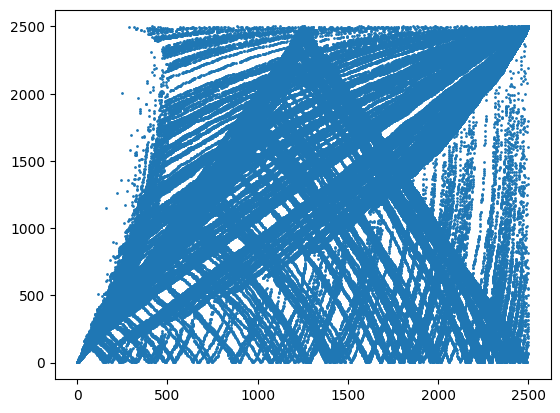

In [36]:
from geometry import build_get_ranks,build_information_imbalance

get_ranks = build_get_ranks(key=subkey_distances, 
                            sample_size=Ns, 
                            distance_fn=L2_distance, 
                            )
x_ranks,y_ranks = get_ranks(X,Y)
np.savez("ranks.npz", x_ranks=x_ranks, y_ranks=y_ranks)
del x_ranks,y_ranks

x_ranks, y_ranks = np.load("ranks.npz").values()

plt.scatter(x_ranks[::20],y_ranks[::20],s=1)
shuffled_indices = np.random.permutation(x_ranks.shape[0])
x_ranks = x_ranks[shuffled_indices]

In [37]:
II_fn = build_information_imbalance(k=1)
II_fn(x_ranks,y_ranks)

(Array(0.9886457, dtype=float32), Array(0.9951366, dtype=float32))

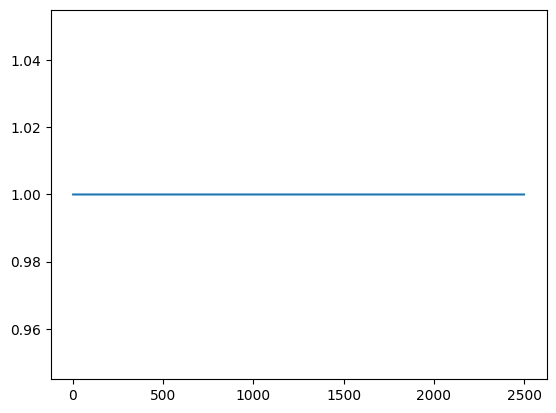

In [38]:
v,c = np.unique(x_ranks[0],return_counts=True)
plt.plot(v,c)